# 10 · Step 10: The contrast case, what goes wrong without a random test (gate K9)
**The question:** most companies never run a random test. They target the customers they like, then compare them with everyone else. What answer does that give, and can it be trusted?

**Data:** Dunnhumby *The Complete Journey*: 2,469 US grocery households, 1 year of baskets, 27 real marketing campaigns. **The company chose whom to target**, so there is no random control group.

**The test case:** Campaign 8 (Type A, 8 May to 25 Jun 2017, weeks 20-26), sent to about 1,000 households.

| Approach | What it compares |
|---|---|
| Naive | targeted households vs everyone else, during the campaign |
| Fair attempt 1 | targeted vs **never-targeted** look-alikes (matched on pre-campaign spend), change over time |
| Fair attempt 2 | targeted vs look-alikes the company **targeted later** (similar kind of customer), change over time |

## Cell 0 · Setup

In [1]:
import pandas as pd, numpy as np, duckdb, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 200)
D = Path('..') / 'data' / 'parquet'
q = lambda s: duckdb.sql(s.replace('{D}', D.as_posix())).df()
W = q("SELECT household_id, week, SUM(sales_value) spend, COUNT(DISTINCT basket_id) trips FROM '{D}/transactions.parquet' GROUP BY 1, 2")
S = W.pivot_table(index='household_id', columns='week', values='spend', fill_value=0)      # weekly spend, $ per household
TR = W.pivot_table(index='household_id', columns='week', values='trips', fill_value=0)
C = q("SELECT household_id, MAX(campaign_id = 8)::INT c8, MAX(campaign_id = 13)::INT c13, MAX(campaign_id = 18)::INT c18, MAX(campaign_id = 27)::INT c27 FROM '{D}/campaigns.parquet' GROUP BY 1").set_index('household_id')
C = C.reindex(S.index).fillna(0).astype(int)
ever = set(q("SELECT DISTINCT household_id FROM '{D}/campaigns.parquet'").household_id)
targeted = list(S.index[(C.c8 == 1) & (C.c27 == 0)])                                        # campaign 8 (not in the earlier campaign 27)
never = [h for h in S.index if h not in ever]                                                  # never targeted by any campaign
later = list(S.index[(C.c8 == 0) & (C.c27 == 0) & ((C.c13 == 1) | (C.c18 == 1))])             # targeted only in later Type A campaigns
PRE, PLACEBO, CAMP = range(2, 14), range(14, 20), range(20, 27)                                 # matching weeks, check weeks, campaign weeks
CHECKS = {}
print(f'{len(S):,} households | campaign 8 targets: {len(targeted):,} | never targeted: {len(never):,} | targeted later: {len(later):,}')

2,469 households | campaign 8 targets: 825 | never targeted: 910 | targeted later: 304


## Part A · The naive report
"Households that got Campaign 8 spent X times more during the campaign." This is how most campaign results are reported.

,targeted $/week,never targeted $/week,ratio
before (weeks 2-13),56.6,9.0,6.29
during campaign (weeks 20-26),55.0,9.9,5.56


Naive report: targeted households spent 5.6x more during the campaign.
But they already spent 6.3x more BEFORE it started: the company picked its best customers. The gap is selection, not the campaign.


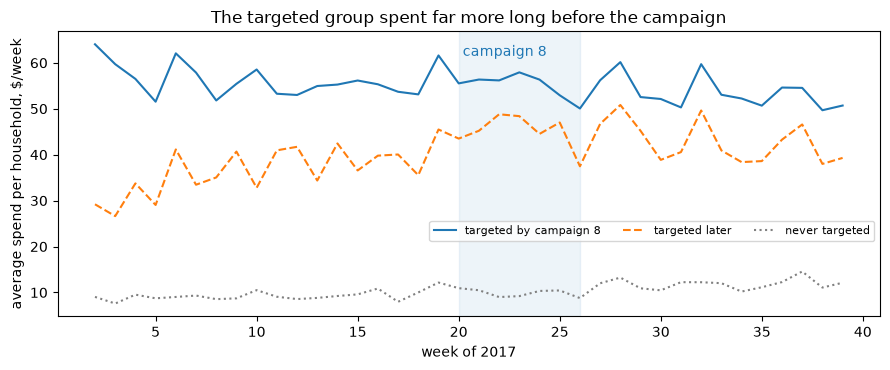

In [2]:
wk = lambda ids, w: S.loc[ids, list(w)].mean(axis=1)
naive = wk(targeted, CAMP).mean() / wk(never, CAMP).mean()
before = wk(targeted, PRE).mean() / wk(never, PRE).mean()
A = pd.DataFrame({'targeted $/week': [wk(targeted, PRE).mean(), wk(targeted, CAMP).mean()], 'never targeted $/week': [wk(never, PRE).mean(), wk(never, CAMP).mean()]},
                 index=['before (weeks 2-13)', 'during campaign (weeks 20-26)']).round(1)
A['ratio'] = (A.iloc[:, 0] / A.iloc[:, 1]).round(2); display(A)
print(f'Naive report: targeted households spent {naive:.1f}x more during the campaign.')
print(f'But they already spent {before:.1f}x more BEFORE it started: the company picked its best customers. The gap is selection, not the campaign.')
CHECKS['Naive report shows a big effect (over 3x)'] = naive > 3
CHECKS['The gap already existed before the campaign (selection bias, over 3x)'] = before > 3
fig, ax = plt.subplots(figsize=(9, 3.8)); weeks = range(2, 40)
for ids, lab, col, ls in [(targeted, 'targeted by campaign 8', 'tab:blue', '-'), (later, 'targeted later', 'tab:orange', '--'), (never, 'never targeted', 'grey', ':')]:
    ax.plot(list(weeks), S.loc[ids, list(weeks)].mean().values, color=col, ls=ls, label=lab)
ax.axvspan(20, 26, color='tab:blue', alpha=0.08); ax.text(20.2, ax.get_ylim()[1] * 0.92, 'campaign 8', color='tab:blue')
ax.set_xlabel('week of 2017'); ax.set_ylabel('average spend per household, $/week')
ax.set_title('The targeted group spent far more long before the campaign'); ax.legend(fontsize=8, loc='center right', bbox_to_anchor=(1, 0.3), ncol=3); plt.tight_layout(); plt.show()

## Part B · Two careful attempts, two different answers
The best you can do without a random test:
1. **Match:** for each targeted household, find the most similar control household on spend in weeks 2-13 and trips (drop the worst 10% of matches).
2. **Placebo check:** in weeks 14-19 there was no campaign yet, so the matched pairs should spend the same. If they do not, the match is not trustworthy.
3. **Effect = difference-in-differences:** (targeted − control) during the campaign, minus (targeted − control) in the placebo weeks. A 95% range comes from 1,000 bootstrap repeats.

The same method is run twice, with two reasonable choices of control group.

In [3]:
rng = np.random.default_rng(7)
def careful(treat, pool, label):
    def feats(ids):
        X = pd.DataFrame(index=ids); w = list(PRE)
        for i in range(0, len(w), 4): X[f's{i}'] = np.log1p(S.loc[ids, w[i:i + 4]].mean(axis=1))
        X['trips'] = np.log1p(TR.loc[ids, w].sum(axis=1)); return X
    XT, XC = feats(treat), feats(pool); sd = pd.concat([XT, XC]).std()
    dist2 = (((XT / sd).values[:, None, :] - (XC / sd).values[None, :, :]) ** 2).sum(-1)
    j, dist = dist2.argmin(1), np.sqrt(dist2.min(1)); keep = dist < np.quantile(dist, 0.9)
    t_ids, c_ids = np.array(treat)[keep], np.array(pool)[j[keep]]
    gap = lambda w: wk(list(t_ids), w).values - wk(list(c_ids), w).values
    plac, did = gap(PLACEBO), gap(CAMP) - gap(PLACEBO); base = wk(list(t_ids), PLACEBO).mean()
    ci = lambda v: np.percentile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(1000)], [2.5, 97.5])
    pl, ef = ci(plac), ci(did)
    return {'control group': label, 'matched pairs': int(keep.sum()), 'placebo gap $/wk': round(plac.mean(), 2),
            'placebo passes': bool(pl[0] <= 0 <= pl[1]), 'effect $/wk': round(did.mean(), 2), 'effect %': round(100 * did.mean() / base, 1),
            'low95 %': round(100 * ef[0] / base, 1), 'high95 %': round(100 * ef[1] / base, 1)}
B = pd.DataFrame([careful(targeted, never, 'never-targeted look-alikes'), careful(targeted, later, 'targeted-later look-alikes')]).set_index('control group')
display(B)
lo, hi = B['effect %'].min(), B['effect %'].max()
print(f'Both matches pass the placebo check, yet the effect is {lo:+.1f}% with one control group and {hi:+.1f}% with the other.')
print('Same campaign, same method, two defensible choices: one says the campaign lost money, the other says it earned it.')
CHECKS['Both careful attempts pass their placebo check'] = bool(B['placebo passes'].all())
CHECKS['The two careful answers disagree in sign'] = (lo < 0) and (hi > 0)

,matched pairs,placebo gap $/wk,placebo passes,effect $/wk,effect %,low95 %,high95 %
control group,,,,,,,
never-targeted look-alikes,742,-2.68,True,5.90,10.7,5.1,16.6
targeted-later look-alikes,742,2.23,True,-3.63,-6.5,-11.2,-1.3


Both matches pass the placebo check, yet the effect is -6.5% with one control group and +10.7% with the other.
Same campaign, same method, two defensible choices: one says the campaign lost money, the other says it earned it.


## Part C · Side by side with a random test

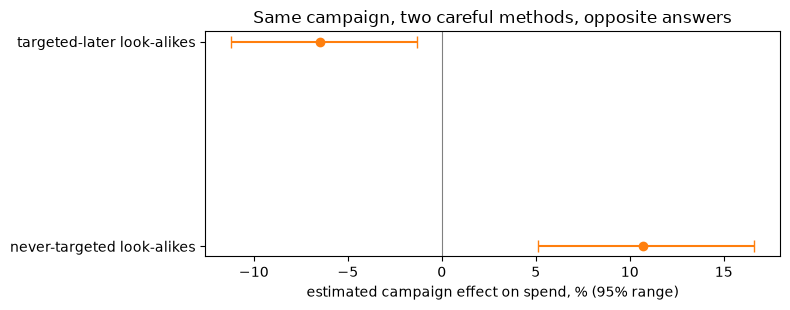

,estimate,95% range / trust
source,,
Complete Journey: naive report,5.6x more spend,none: mostly selection
"Complete Journey: careful, never-targeted controls",+10.7%,+5.1% to +16.6%
"Complete Journey: careful, targeted-later controls",-6.5%,-11.2% to -1.3%
X5 random test (Step 1),+3.3 pts buy rate,"+2.9 to +3.8 pts, one answer"


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2)); rows = list(B.index)
ax.errorbar(B['effect %'], range(len(rows)), xerr=[B['effect %'] - B['low95 %'], B['high95 %'] - B['effect %']], fmt='o', color='tab:orange', capsize=4)
ax.axvline(0, color='grey', lw=0.8); ax.set_yticks(range(len(rows)), rows); ax.set_xlabel('estimated campaign effect on spend, % (95% range)')
ax.set_title('Same campaign, two careful methods, opposite answers'); plt.tight_layout(); plt.show()
SUM = pd.DataFrame([
    ('Complete Journey: naive report', f'{naive:.1f}x more spend', 'none: mostly selection'),
    ('Complete Journey: careful, never-targeted controls', f"{B['effect %'].iloc[0]:+.1f}%", f"{B['low95 %'].iloc[0]:+.1f}% to {B['high95 %'].iloc[0]:+.1f}%"),
    ('Complete Journey: careful, targeted-later controls', f"{B['effect %'].iloc[1]:+.1f}%", f"{B['low95 %'].iloc[1]:+.1f}% to {B['high95 %'].iloc[1]:+.1f}%"),
    ('X5 random test (Step 1)', '+3.3 pts buy rate', '+2.9 to +3.8 pts, one answer'),
], columns=['source', 'estimate', '95% range / trust']).set_index('source'); display(SUM)

## K9 verdict
- The naive report must look impressive, and the pre-campaign gap must show it is selection.
- Careful methods must pass their own placebo checks, yet still disagree: without randomisation the answer depends on an untestable choice.

In [5]:
for k_, v in CHECKS.items(): print(f'{"PASS" if v else "FAIL"}  {k_}')
print('\nK9 VERDICT:', 'PASS' if all(CHECKS.values()) else 'REVIEW')

PASS  Naive report shows a big effect (over 3x)
PASS  The gap already existed before the campaign (selection bias, over 3x)
PASS  Both careful attempts pass their placebo check
PASS  The two careful answers disagree in sign

K9 VERDICT: PASS


## Your notes
- Why did the targeted group spend more before the campaign even started?
- Both matches passed the placebo check. Why do they still disagree?
- What would you tell a manager who shows you a "5.6x" campaign result?